# 🚦 Pipeline Xử Lý Dữ Liệu YOLOv8 - Biển Báo Giao Thông Việt Nam

## Mục tiêu
Xây dựng pipeline xử lý dữ liệu hoàn chỉnh cho bài toán nhận diện biển báo giao thông sử dụng YOLOv8.

## Pipeline Overview
1. **Import & Configuration** - Cấu hình môi trường
2. **Label Grouping** - Gộp 7 classes → 3 super-classes
3. **EDA** - Phân tích phân bố class, kích thước bounding box
4. **Data Cleaning** - Lọc ảnh mờ, trùng lặp, bounding box lỗi
5. **Data Splitting** - Chia Train/Val/Test (70/20/10)
6. **Data Augmentation** - Tăng cường dữ liệu cho class thiểu số

## Dataset Structure
```
Data_Raw/YOLO_Dataset/          ← Input (raw data)
Data_Processed/YOLO_Processed/  ← Output (processed data)
Pictures/YOLO_Processing/       ← Visualization outputs
```

## 1. Import Libraries & Configuration

**Thư viện chính:**
- `cv2` - Xử lý ảnh, blur detection (Laplacian variance)
- `imagehash` - Perceptual hashing để phát hiện ảnh trùng lặp
- `albumentations` - Data augmentation cho object detection
- `sklearn` - Stratified sampling

In [16]:
# =============================================================================
# CELL 1: IMPORT LIBRARIES & CONFIGURATION
# =============================================================================

import os
import sys
import shutil
import yaml
import random
from collections import Counter, defaultdict
from typing import Dict, List, Tuple, Optional
from pathlib import Path

from tqdm import tqdm
from matplotlib.patches import Rectangle

# Data Science & Visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Image Processing
import cv2
from PIL import Image

# Sklearn - Stratified Splitting
from sklearn.model_selection import train_test_split

# =============================================================================
# SETUP PROJECT PATHS
# =============================================================================
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent      # Traffic_Sign_Project/
PARENT_DIR = PROJECT_ROOT.parent        # Project_DL/

# Thêm project vào Python path để import Utils
sys.path.insert(0, str(PROJECT_ROOT))

# =============================================================================
# IMPORT HELPER FUNCTIONS
# =============================================================================
try:
    from Utils.helper_functions import (
        get_paths,
        get_yolo_picture_paths,
        TRAFFIC_SIGN_CLASSES,
        YOLO_CLASS_MAPPING,
        YOLO_SUPERCLASS_NAMES,
        calculate_blur_score,
        save_figure,
        save_image,
    )
    PATHS = get_paths()
    YOLO_PICS = get_yolo_picture_paths()
    USE_HELPER = True
    print("✅ Imported helper functions from Utils")
except ImportError as e:
    USE_HELPER = False
    print(f"⚠️ Could not import Utils: {e}")

# =============================================================================
# OPTIONAL LIBRARIES
# =============================================================================
try:
    import imagehash
    IMAGEHASH_AVAILABLE = True
except ImportError:
    IMAGEHASH_AVAILABLE = False
    print("⚠️ imagehash not installed. Run: pip install imagehash")

try:
    import albumentations as A
    ALBUMENTATIONS_AVAILABLE = True
except ImportError:
    ALBUMENTATIONS_AVAILABLE = False
    print("⚠️ albumentations not installed. Run: pip install albumentations")

# =============================================================================
# VISUALIZATION SETTINGS
# =============================================================================
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

# Reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# =============================================================================
# DATA PATHS - Sử dụng cấu trúc thư mục chuẩn
# =============================================================================
if USE_HELPER:
    INPUT_DIR = PATHS['yolo_raw_data']
    OUTPUT_DIR = PATHS['yolo_processed']
    PICTURES_DIR = PATHS['yolo_pictures']
else:
    INPUT_DIR = PARENT_DIR / 'Data_Raw' / 'YOLO_Dataset'
    OUTPUT_DIR = PARENT_DIR / 'Data_Processed' / 'YOLO_Processed'
    PICTURES_DIR = PARENT_DIR / 'Pictures' / 'YOLO_Processing'

# =============================================================================
# CONFIGURATION
# =============================================================================
CONFIG = {
    # Split ratios
    'train_ratio': 0.70,
    'val_ratio': 0.20,
    'test_ratio': 0.10,
    
    # Cleaning thresholds
    'blur_threshold': 100,      # Laplacian variance < 100 = blurry
    'min_box_area': 0.0001,     # Min bbox area (normalized)
    'max_box_area': 0.95,       # Max bbox area (normalized)
    'phash_threshold': 5,       # pHash distance <= 5 = similar
    
    # Augmentation
    'augment_multiplier': 2,
    
    # Class mapping: 7 classes → 3 super-classes
    'class_mapping': {
        0: 0,  # Cam nguoc chieu → Prohibitory
        1: 0,  # Cam dung va do → Prohibitory
        2: 0,  # Cam re → Prohibitory
        3: 0,  # Gioi han toc do → Prohibitory
        4: 0,  # Cam con lai → Prohibitory
        5: 1,  # Nguy hiem → Danger
        6: 2,  # Hieu lenh → Mandatory
    },
    
    'new_class_names': ['Prohibitory', 'Danger', 'Mandatory'],
    'original_class_names': [
        'Cam nguoc chieu', 'Cam dung va do', 'Cam re',
        'Gioi han toc do', 'Cam con lai', 'Nguy hiem', 'Hieu lenh'
    ]
}

# =============================================================================
# PRINT CONFIGURATION
# =============================================================================
print("=" * 60)
print("✅ CONFIGURATION LOADED")
print("=" * 60)
print(f"\n📁 Paths:")
print(f"   Input:    {INPUT_DIR}")
print(f"   Output:   {OUTPUT_DIR}")
print(f"   Pictures: {PICTURES_DIR}")
print(f"\n📊 Split: Train {CONFIG['train_ratio']*100:.0f}% | Val {CONFIG['val_ratio']*100:.0f}% | Test {CONFIG['test_ratio']*100:.0f}%")
print(f"\n🔧 Settings:")
print(f"   Blur Threshold: {CONFIG['blur_threshold']}")
print(f"   pHash Threshold: {CONFIG['phash_threshold']}")
print(f"   ImageHash: {'✅' if IMAGEHASH_AVAILABLE else '❌'}")
print(f"   Albumentations: {'✅' if ALBUMENTATIONS_AVAILABLE else '❌'}")

✅ Imported helper functions from Utils
✅ CONFIGURATION LOADED

📁 Paths:
   Input:    c:\Users\sangg\Desktop\Project_DL\Data_Raw\YOLO_Dataset
   Output:   c:\Users\sangg\Desktop\Project_DL\Data_Processed\YOLO_Processed
   Pictures: c:\Users\sangg\Desktop\Project_DL\Pictures\YOLO_Processing

📊 Split: Train 70% | Val 20% | Test 10%

🔧 Settings:
   Blur Threshold: 100
   pHash Threshold: 5
   ImageHash: ✅
   Albumentations: ✅


In [17]:
# =============================================================================
# CELL 2: SETUP OUTPUT DIRECTORIES
# =============================================================================

# Tạo các thư mục output
GROUPED_DIR = OUTPUT_DIR / 'grouped'
CLEANED_DIR = OUTPUT_DIR / 'cleaned'
BLUR_DIR = OUTPUT_DIR / 'blur_filtered'
DEDUP_DIR = OUTPUT_DIR / 'deduplicated'
IGNORED_DIR = OUTPUT_DIR / 'ignored'
TRAIN_DIR = OUTPUT_DIR / 'train'
VAL_DIR = OUTPUT_DIR / 'val'
TEST_DIR = OUTPUT_DIR / 'test'

# Thư mục lưu visualization
if USE_HELPER:
    PIC_RAW_SAMPLES = YOLO_PICS['01_raw_samples']
    PIC_CLASS_DIST = YOLO_PICS['02_class_distribution']
    PIC_BLUR = YOLO_PICS['03_blur_detection']
    PIC_DUPLICATE = YOLO_PICS['04_duplicate_detection']
    PIC_AUGMENT = YOLO_PICS['05_augmentation']
    PIC_FINAL_DIST = YOLO_PICS['06_final_distribution']
    PIC_ANNOTATIONS = YOLO_PICS['07_sample_annotations']
else:
    PIC_RAW_SAMPLES = PICTURES_DIR / '01_Raw_Samples'
    PIC_CLASS_DIST = PICTURES_DIR / '02_Class_Distribution'
    PIC_BLUR = PICTURES_DIR / '03_Blur_Detection'
    PIC_DUPLICATE = PICTURES_DIR / '04_Duplicate_Detection'
    PIC_AUGMENT = PICTURES_DIR / '05_Augmentation'
    PIC_FINAL_DIST = PICTURES_DIR / '06_Final_Distribution'
    PIC_ANNOTATIONS = PICTURES_DIR / '07_Sample_Annotations'

# Tạo tất cả thư mục
all_dirs = [
    OUTPUT_DIR, GROUPED_DIR, CLEANED_DIR, BLUR_DIR, DEDUP_DIR, IGNORED_DIR,
    TRAIN_DIR, VAL_DIR, TEST_DIR,
    PICTURES_DIR, PIC_RAW_SAMPLES, PIC_CLASS_DIST, PIC_BLUR, PIC_DUPLICATE,
    PIC_AUGMENT, PIC_FINAL_DIST, PIC_ANNOTATIONS
]

for d in all_dirs:
    d.mkdir(parents=True, exist_ok=True)

print("✅ Created output directories:")
print(f"   📂 {OUTPUT_DIR.name}/")
print(f"      ├── grouped/")
print(f"      ├── cleaned/")
print(f"      ├── blur_filtered/")
print(f"      ├── deduplicated/")
print(f"      ├── ignored/")
print(f"      ├── train/")
print(f"      ├── val/")
print(f"      └── test/")
print(f"\n   🖼️ {PICTURES_DIR.name}/ (7 subdirectories)")

✅ Created output directories:
   📂 YOLO_Processed/
      ├── grouped/
      ├── cleaned/
      ├── blur_filtered/
      ├── deduplicated/
      ├── ignored/
      ├── train/
      ├── val/
      └── test/

   🖼️ YOLO_Processing/ (7 subdirectories)


## 2. Load & Explore Dataset

Đọc `data.yaml` và thống kê phân bố class trước khi xử lý.

In [18]:
# =============================================================================
# CELL 3: LOAD & EXPLORE DATASET
# =============================================================================

def load_yaml_config(yaml_path: str) -> dict:
    """Đọc file YAML cấu hình dataset."""
    with open(yaml_path, 'r', encoding='utf-8') as f:
        return yaml.safe_load(f)


def count_dataset_statistics(base_dir: Path) -> Dict[str, dict]:
    """Thống kê số lượng ảnh, labels và class distribution."""
    stats = {}
    
    for subset in ['train', 'val']:
        img_dir = base_dir / subset / 'images'
        lbl_dir = base_dir / subset / 'labels'
        
        if not img_dir.exists():
            print(f"⚠️ Not found: {img_dir}")
            continue
        
        # Count files
        img_files = list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.png')) + list(img_dir.glob('*.jpeg'))
        lbl_files = list(lbl_dir.glob('*.txt')) if lbl_dir.exists() else []
        
        # Count class distribution
        class_counts = Counter()
        total_boxes = 0
        
        for lbl_file in lbl_files:
            with open(lbl_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        try:
                            class_id = int(parts[0])
                            class_counts[class_id] += 1
                            total_boxes += 1
                        except ValueError:
                            continue
        
        stats[subset] = {
            'num_images': len(img_files),
            'num_labels': len(lbl_files),
            'total_boxes': total_boxes,
            'class_distribution': dict(class_counts)
        }
    
    return stats


# Load config
yaml_path = INPUT_DIR / 'data.yaml'
data_config = load_yaml_config(str(yaml_path))

print("=" * 60)
print("📋 DATASET CONFIGURATION")
print("=" * 60)
print(f"Classes: {data_config.get('nc', 'N/A')}")
for idx, name in enumerate(data_config.get('names', [])):
    print(f"  {idx}: {name}")

# Statistics
dataset_stats = count_dataset_statistics(INPUT_DIR)

print("\n" + "=" * 60)
print("📊 DATASET STATISTICS")
print("=" * 60)

for subset, stats in dataset_stats.items():
    print(f"\n🗂️ {subset.upper()}:")
    print(f"   Images: {stats['num_images']} | Labels: {stats['num_labels']} | Boxes: {stats['total_boxes']}")
    
    for class_id, count in sorted(stats['class_distribution'].items()):
        class_name = CONFIG['original_class_names'][class_id] if class_id < len(CONFIG['original_class_names']) else f"Unknown_{class_id}"
        pct = (count / stats['total_boxes'] * 100) if stats['total_boxes'] > 0 else 0
        print(f"      {class_id}: {class_name} - {count} ({pct:.1f}%)")

📋 DATASET CONFIGURATION
Classes: 7
  0: Cam nguoc chieu
  1: Cam dung va do
  2: Cam re
  3: Gioi han toc do
  4: Cam con lai
  5: Nguy hiem
  6: Hieu lenh

📊 DATASET STATISTICS

🗂️ TRAIN:
   Images: 3600 | Labels: 3600 | Boxes: 8860
      0: Cam nguoc chieu - 1162 (13.1%)
      1: Cam dung va do - 1789 (20.2%)
      2: Cam re - 443 (5.0%)
      3: Gioi han toc do - 759 (8.6%)
      4: Cam con lai - 1452 (16.4%)
      5: Nguy hiem - 2409 (27.2%)
      6: Hieu lenh - 846 (9.5%)

🗂️ VAL:
   Images: 900 | Labels: 900 | Boxes: 2140
      0: Cam nguoc chieu - 254 (11.9%)
      1: Cam dung va do - 432 (20.2%)
      2: Cam re - 113 (5.3%)
      3: Gioi han toc do - 190 (8.9%)
      4: Cam con lai - 335 (15.7%)
      5: Nguy hiem - 640 (29.9%)
      6: Hieu lenh - 176 (8.2%)


## 3. Label Grouping - Gộp về 3 Super-classes

| Original Class | → | Super-class |
|----------------|---|-------------|
| 0-4: Các biển cấm | → | 0: Prohibitory |
| 5: Nguy hiểm | → | 1: Danger |
| 6: Hiệu lệnh | → | 2: Mandatory |

🏷️ LABEL GROUPING

📊 Visualization:


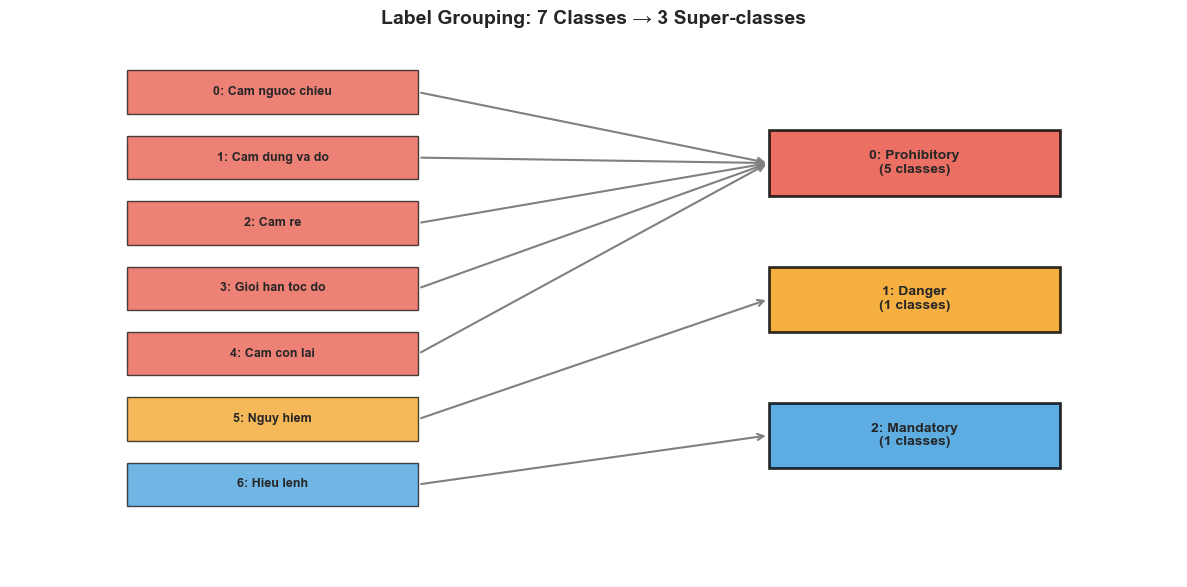

✅ Saved: c:\Users\sangg\Desktop\Project_DL\Pictures\YOLO_Processing\02_Class_Distribution\label_grouping.png

🔄 Applying grouping...


Grouping val: 100%|██████████| 900/900 [00:05<00:00, 153.29it/s]


✅ Complete!
   Files: 4,500
   Boxes: 11,000
   Output: c:\Users\sangg\Desktop\Project_DL\Data_Processed\YOLO_Processed\grouped


In [19]:
# =============================================================================
# CELL 4: LABEL GROUPING
# =============================================================================

def create_class_mapping_visualization():
    """Tạo visualization cho label mapping."""
    _, ax = plt.subplots(figsize=(12, 6))
    
    original_classes = CONFIG['original_class_names']
    new_classes = CONFIG['new_class_names']
    mapping = CONFIG['class_mapping']
    colors = ['#e74c3c', '#f39c12', '#3498db']
    
    # Original classes (left)
    left_x = 0.1
    for i, name in enumerate(original_classes):
        y = 0.85 - i * 0.12
        new_class_id = mapping.get(i, 0)
        ax.add_patch(Rectangle((left_x, y), 0.25, 0.08, 
                               facecolor=colors[new_class_id], alpha=0.7,
                               edgecolor='black', linewidth=1))
        ax.text(left_x + 0.125, y + 0.04, f"{i}: {name}", 
               ha='center', va='center', fontsize=9, fontweight='bold')
    
    # New classes (right)
    right_x = 0.65
    new_class_counts = Counter(mapping.values())
    y_positions = [0.7, 0.45, 0.2]
    
    for i, name in enumerate(new_classes):
        y = y_positions[i]
        count = new_class_counts.get(i, 0)
        ax.add_patch(Rectangle((right_x, y), 0.25, 0.12,
                               facecolor=colors[i], alpha=0.8,
                               edgecolor='black', linewidth=2))
        ax.text(right_x + 0.125, y + 0.06, f"{i}: {name}\n({count} classes)", 
               ha='center', va='center', fontsize=10, fontweight='bold')
    
    # Arrows
    for i in range(len(original_classes)):
        y_start = 0.85 - i * 0.12 + 0.04
        new_id = mapping.get(i, 0)
        y_end = y_positions[new_id] + 0.06
        ax.annotate('', xy=(right_x, y_end), xytext=(left_x + 0.25, y_start),
                   arrowprops=dict(arrowstyle='->', color='gray', lw=1.5))
    
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title('Label Grouping: 7 Classes → 3 Super-classes', fontsize=14, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    
    # Save
    save_path = PIC_CLASS_DIST / 'label_grouping.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {save_path}")


def apply_label_grouping(input_dir: Path, output_dir: Path, mapping: dict) -> Tuple[int, int]:
    """Áp dụng label grouping lên dataset."""
    processed_files = 0
    mapped_boxes = 0
    
    for subset in ['train', 'val']:
        src_img_dir = input_dir / subset / 'images'
        src_lbl_dir = input_dir / subset / 'labels'
        dst_img_dir = output_dir / 'grouped' / subset / 'images'
        dst_lbl_dir = output_dir / 'grouped' / subset / 'labels'
        
        dst_img_dir.mkdir(parents=True, exist_ok=True)
        dst_lbl_dir.mkdir(parents=True, exist_ok=True)
        
        if not src_lbl_dir.exists():
            continue
        
        label_files = list(src_lbl_dir.glob('*.txt'))
        
        for lbl_file in tqdm(label_files, desc=f'Grouping {subset}'):
            new_lines = []
            with open(lbl_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        try:
                            old_class_id = int(parts[0])
                            new_class_id = mapping.get(old_class_id, 0)
                            new_line = f"{new_class_id} {' '.join(parts[1:])}\n"
                            new_lines.append(new_line)
                            mapped_boxes += 1
                        except ValueError:
                            continue
            
            if new_lines:
                # Write new label
                with open(dst_lbl_dir / lbl_file.name, 'w') as f:
                    f.writelines(new_lines)
                
                # Copy image
                base_name = lbl_file.stem
                for ext in ['.png', '.jpg', '.jpeg']:
                    src_img = src_img_dir / f"{base_name}{ext}"
                    if src_img.exists():
                        shutil.copy2(src_img, dst_img_dir / f"{base_name}{ext}")
                        break
                
                processed_files += 1
    
    return processed_files, mapped_boxes


# =============================================================================
# RUN LABEL GROUPING
# =============================================================================
print("=" * 60)
print("🏷️ LABEL GROUPING")
print("=" * 60)

print("\n📊 Visualization:")
create_class_mapping_visualization()

print("\n🔄 Applying grouping...")
num_files, num_boxes = apply_label_grouping(INPUT_DIR, OUTPUT_DIR, CONFIG['class_mapping'])

print(f"\n✅ Complete!")
print(f"   Files: {num_files:,}")
print(f"   Boxes: {num_boxes:,}")
print(f"   Output: {GROUPED_DIR}")

## 4. Exploratory Data Analysis (EDA)

Phân tích phân bố class và kích thước bounding box sau khi grouping.

📊 EXPLORATORY DATA ANALYSIS
✅ Collected 11,000 bounding boxes


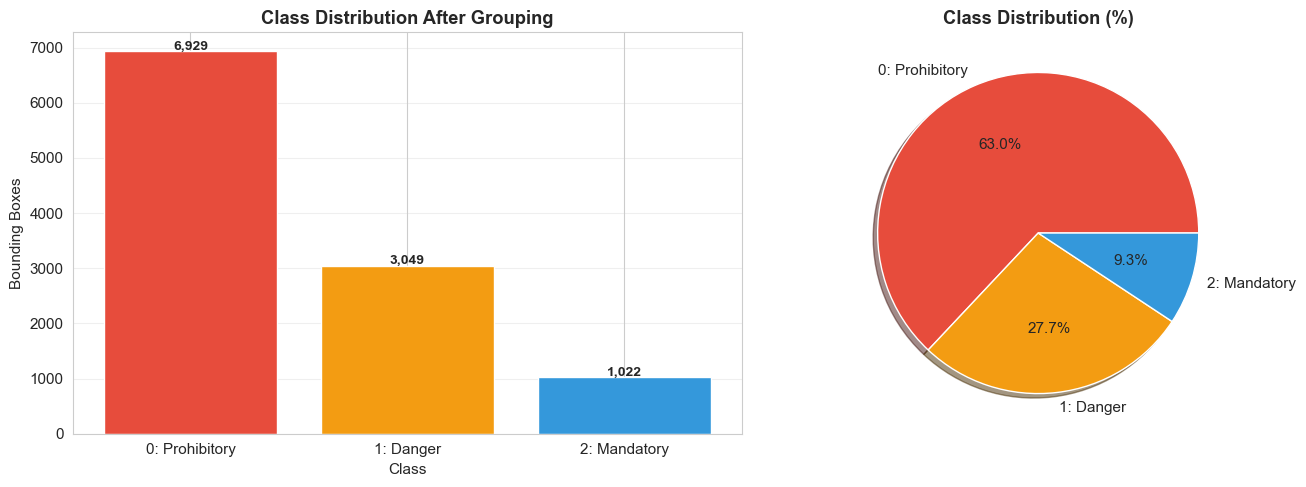

✅ Saved: c:\Users\sangg\Desktop\Project_DL\Pictures\YOLO_Processing\02_Class_Distribution\class_distribution.png

📊 Class Imbalance:
   0 (Prohibitory): 6,929 | 1.00x
   1 (Danger): 3,049 | 2.27x
   2 (Mandatory): 1,022 | 6.78x


In [20]:
# =============================================================================
# CELL 5: EDA - CLASS DISTRIBUTION
# =============================================================================

def collect_bbox_data(base_dir: Path) -> pd.DataFrame:
    """Thu thập thông tin bounding box từ dataset."""
    records = []
    
    for subset in ['train', 'val']:
        lbl_dir = base_dir / 'grouped' / subset / 'labels'
        if not lbl_dir.exists():
            continue
        
        for lbl_file in lbl_dir.glob('*.txt'):
            with open(lbl_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        try:
                            class_id = int(parts[0])
                            x_c, y_c, w, h = map(float, parts[1:5])
                            records.append({
                                'subset': subset,
                                'file': lbl_file.name,
                                'class_id': class_id,
                                'x_center': x_c,
                                'y_center': y_c,
                                'width': w,
                                'height': h,
                                'area': w * h,
                                'aspect_ratio': w / (h + 1e-8)
                            })
                        except ValueError:
                            continue
    
    return pd.DataFrame(records)


def plot_class_distribution(df: pd.DataFrame, class_names: List[str]):
    """Vẽ biểu đồ phân bố class."""
    _, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    class_counts = df['class_id'].value_counts().sort_index()
    class_labels = [f"{int(i)}: {class_names[int(i)]}" for i in class_counts.index]
    colors = ['#e74c3c', '#f39c12', '#3498db']
    
    # Bar chart
    bars = axes[0].bar(class_labels, class_counts.values, 
                       color=[colors[int(i)] for i in class_counts.index])
    axes[0].set_xlabel('Class')
    axes[0].set_ylabel('Bounding Boxes')
    axes[0].set_title('Class Distribution After Grouping', fontweight='bold')
    for bar, count in zip(bars, class_counts.values):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                    f'{count:,}', ha='center', fontsize=10, fontweight='bold')
    axes[0].grid(axis='y', alpha=0.3)
    
    # Pie chart
    axes[1].pie(class_counts.values, labels=class_labels, autopct='%1.1f%%',
               colors=[colors[int(i)] for i in class_counts.index], shadow=True)
    axes[1].set_title('Class Distribution (%)', fontweight='bold')
    
    plt.tight_layout()
    save_path = PIC_CLASS_DIST / 'class_distribution.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {save_path}")
    
    # Imbalance analysis
    print("\n📊 Class Imbalance:")
    max_count = int(class_counts.max())
    for idx in class_counts.index:
        count = int(class_counts.loc[idx])
        ratio = max_count / count if count > 0 else float('inf')
        print(f"   {int(idx)} ({class_names[int(idx)]}): {count:,} | {ratio:.2f}x")


# Run EDA
print("=" * 60)
print("📊 EXPLORATORY DATA ANALYSIS")
print("=" * 60)

df_bbox = collect_bbox_data(OUTPUT_DIR)

if len(df_bbox) > 0:
    print(f"✅ Collected {len(df_bbox):,} bounding boxes")
    df_bbox['class_name'] = df_bbox['class_id'].map(
        lambda x: CONFIG['new_class_names'][int(x)] if int(x) < len(CONFIG['new_class_names']) else f'Unknown_{x}'
    )
    plot_class_distribution(df_bbox, CONFIG['new_class_names'])
else:
    print("⚠️ No data found. Run Label Grouping first.")

### 4.2 Bounding Box Size Analysis

Phân tích Width/Height, Aspect Ratio và Area distribution.


📏 BOUNDING BOX SIZE ANALYSIS


C:\Users\sangg\AppData\Local\Temp\ipykernel_13724\4147764661.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1, 0].boxplot(aspect_data, patch_artist=True, labels=labels)


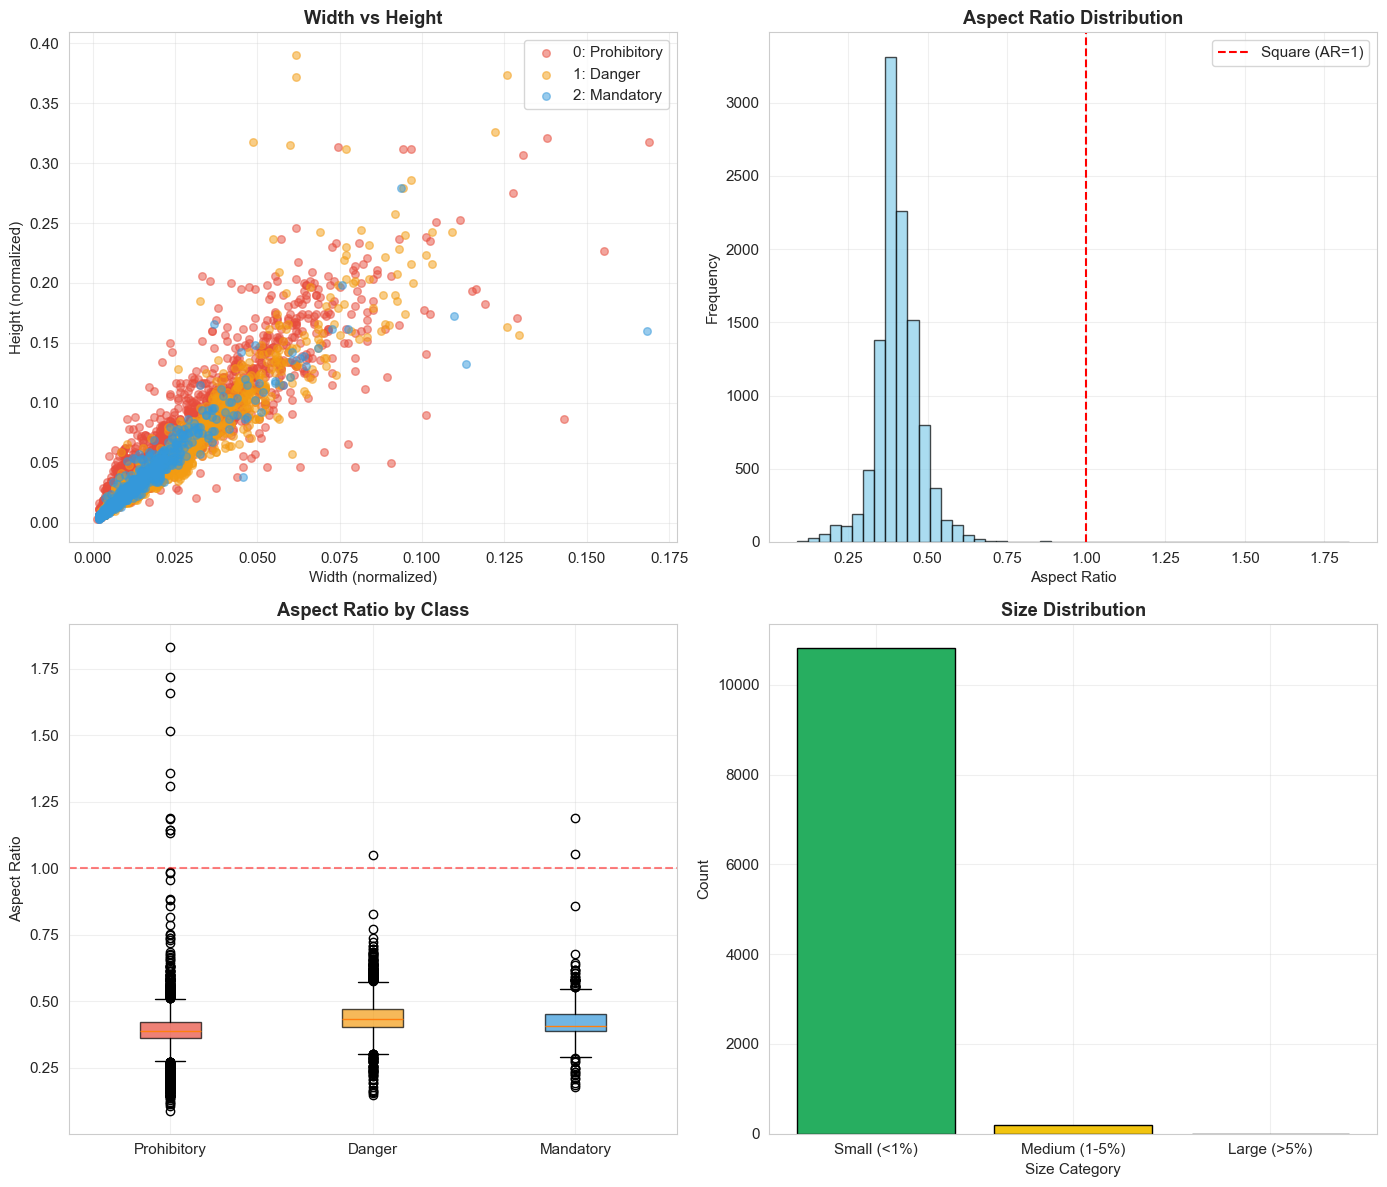

✅ Saved: c:\Users\sangg\Desktop\Project_DL\Pictures\YOLO_Processing\02_Class_Distribution\bbox_analysis.png


In [21]:
# =============================================================================
# CELL 6: BOUNDING BOX SIZE ANALYSIS
# =============================================================================

def plot_bbox_analysis(df: pd.DataFrame, class_names: List[str]):
    """Vẽ biểu đồ phân tích kích thước bounding box."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    colors = ['#e74c3c', '#f39c12', '#3498db']
    
    # Plot 1: Width vs Height scatter
    for class_id in df['class_id'].unique():
        class_data = df[df['class_id'] == class_id]
        cid = int(class_id)
        axes[0, 0].scatter(class_data['width'], class_data['height'],
                          c=colors[cid], label=f"{cid}: {class_names[cid]}",
                          alpha=0.5, s=30)
    axes[0, 0].set_xlabel('Width (normalized)')
    axes[0, 0].set_ylabel('Height (normalized)')
    axes[0, 0].set_title('Width vs Height', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)
    
    # Plot 2: Aspect Ratio histogram
    axes[0, 1].hist(df['aspect_ratio'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
    axes[0, 1].axvline(x=1.0, color='red', linestyle='--', label='Square (AR=1)')
    axes[0, 1].set_xlabel('Aspect Ratio')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_title('Aspect Ratio Distribution', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)
    
    # Plot 3: Aspect Ratio by class
    aspect_data = [df[df['class_id'] == i]['aspect_ratio'].values 
                   for i in sorted(df['class_id'].unique())]
    labels = [class_names[int(i)] for i in sorted(df['class_id'].unique())]
    bp = axes[1, 0].boxplot(aspect_data, patch_artist=True, labels=labels)
    for patch, color in zip(bp['boxes'], [colors[int(i)] for i in sorted(df['class_id'].unique())]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[1, 0].axhline(y=1.0, color='red', linestyle='--', alpha=0.5)
    axes[1, 0].set_ylabel('Aspect Ratio')
    axes[1, 0].set_title('Aspect Ratio by Class', fontweight='bold')
    axes[1, 0].grid(alpha=0.3)
    
    # Plot 4: Area distribution
    df_copy = df.copy()
    df_copy['size_category'] = pd.cut(df_copy['area'], bins=[0, 0.01, 0.05, 1.0],
                                      labels=['Small (<1%)', 'Medium (1-5%)', 'Large (>5%)'])
    size_counts = df_copy['size_category'].value_counts()
    axes[1, 1].bar(size_counts.index.astype(str), size_counts.values,
                  color=['#27ae60', '#f1c40f', '#e74c3c'], edgecolor='black')
    axes[1, 1].set_xlabel('Size Category')
    axes[1, 1].set_ylabel('Count')
    axes[1, 1].set_title('Size Distribution', fontweight='bold')
    axes[1, 1].grid(alpha=0.3)
    
    plt.tight_layout()
    save_path = PIC_CLASS_DIST / 'bbox_analysis.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {save_path}")


# Run analysis
print("\n" + "=" * 60)
print("📏 BOUNDING BOX SIZE ANALYSIS")
print("=" * 60)

if len(df_bbox) > 0:
    plot_bbox_analysis(df_bbox, CONFIG['new_class_names'])
else:
    print("⚠️ No data. Run Label Grouping first.")

## 5. Data Cleaning

**Các bước làm sạch:**
1. **Integrity Check** - Loại bbox có tọa độ không hợp lệ (ngoài [0,1], area=0, area>95%)
2. **Blur Detection** - Lọc ảnh mờ bằng Laplacian variance (threshold=100)
3. **Deduplication** - Xóa ảnh trùng bằng pHash (distance ≤ 5)

In [22]:
# =============================================================================
# CELL 7: INTEGRITY CHECK
# =============================================================================

def validate_bounding_box(x_c: float, y_c: float, w: float, h: float,
                         min_area: float, max_area: float) -> Tuple[bool, str]:
    """Validate bounding box coordinates."""
    # Check bounds
    if not (0 <= x_c <= 1 and 0 <= y_c <= 1):
        return False, "out_of_bounds"
    if not (0 < w <= 1 and 0 < h <= 1):
        return False, "out_of_bounds"
    
    # Check partially outside
    if (x_c - w/2 < 0 or x_c + w/2 > 1 or y_c - h/2 < 0 or y_c + h/2 > 1):
        return False, "partially_outside"
    
    # Check area
    area = w * h
    if area <= 0:
        return False, "zero_area"
    if area < min_area:
        return False, "too_small"
    if area > max_area:
        return False, "too_large"
    
    return True, "valid"


def clean_labels_integrity(input_dir: Path, output_dir: Path,
                          min_area: float, max_area: float) -> dict:
    """Làm sạch labels dựa trên integrity check."""
    stats = {
        'total_boxes': 0, 'valid_boxes': 0,
        'removed': {'out_of_bounds': 0, 'partially_outside': 0, 'zero_area': 0, 'too_small': 0, 'too_large': 0},
        'files_processed': 0, 'files_removed': 0
    }
    
    for subset in ['train', 'val']:
        src_img_dir = input_dir / 'grouped' / subset / 'images'
        src_lbl_dir = input_dir / 'grouped' / subset / 'labels'
        dst_img_dir = output_dir / 'cleaned' / subset / 'images'
        dst_lbl_dir = output_dir / 'cleaned' / subset / 'labels'
        
        dst_img_dir.mkdir(parents=True, exist_ok=True)
        dst_lbl_dir.mkdir(parents=True, exist_ok=True)
        
        if not src_lbl_dir.exists():
            continue
        
        for lbl_file in tqdm(list(src_lbl_dir.glob('*.txt')), desc=f'Integrity {subset}'):
            valid_lines = []
            with open(lbl_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        try:
                            x_c, y_c, w, h = map(float, parts[1:5])
                            stats['total_boxes'] += 1
                            is_valid, reason = validate_bounding_box(x_c, y_c, w, h, min_area, max_area)
                            if is_valid:
                                valid_lines.append(line)
                                stats['valid_boxes'] += 1
                            else:
                                stats['removed'][reason] += 1
                        except ValueError:
                            continue
            
            stats['files_processed'] += 1
            
            if valid_lines:
                with open(dst_lbl_dir / lbl_file.name, 'w') as f:
                    f.writelines(valid_lines)
                # Copy image
                base_name = lbl_file.stem
                for ext in ['.png', '.jpg', '.jpeg']:
                    src_img = src_img_dir / f"{base_name}{ext}"
                    if src_img.exists():
                        shutil.copy2(src_img, dst_img_dir / f"{base_name}{ext}")
                        break
            else:
                stats['files_removed'] += 1
    
    return stats


# Run Integrity Check
print("=" * 60)
print("🔍 INTEGRITY CHECK")
print("=" * 60)

integrity_stats = clean_labels_integrity(OUTPUT_DIR, OUTPUT_DIR, CONFIG['min_box_area'], CONFIG['max_box_area'])

print(f"\n📊 Results:")
print(f"   Total: {integrity_stats['total_boxes']:,} | Valid: {integrity_stats['valid_boxes']:,}")
print(f"   Removed: {integrity_stats['total_boxes'] - integrity_stats['valid_boxes']:,}")
for reason, count in integrity_stats['removed'].items():
    if count > 0:
        print(f"      - {reason}: {count}")

🔍 INTEGRITY CHECK


Integrity val: 100%|██████████| 900/900 [00:15<00:00, 59.38it/s] 


📊 Results:
   Total: 11,000 | Valid: 8,082
   Removed: 2,918
      - partially_outside: 21
      - too_small: 2897



🔍 BLUR DETECTION


Blur val: 100%|██████████| 774/774 [00:36<00:00, 20.99it/s]



📊 Results:
   Total: 3,828 | Sharp: 3,654 | Blurry: 174


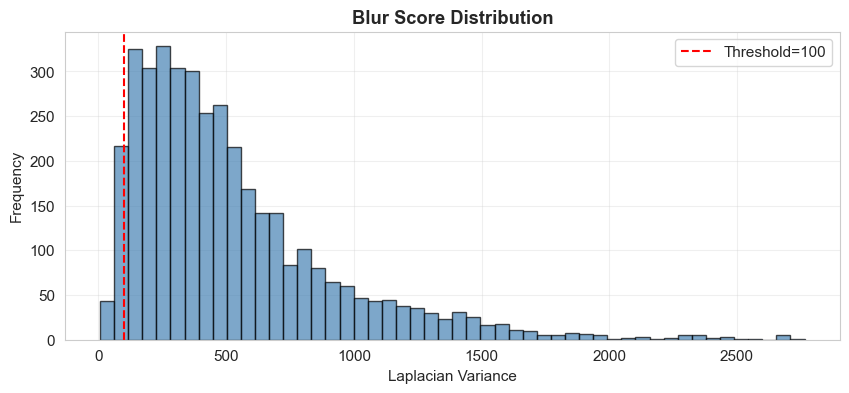

✅ Saved: c:\Users\sangg\Desktop\Project_DL\Pictures\YOLO_Processing\03_Blur_Detection\blur_distribution.png


In [23]:
# =============================================================================
# CELL 8: BLUR DETECTION
# =============================================================================

def calculate_laplacian_variance(image_path: Path) -> float:
    """Tính Laplacian variance để đo độ sắc nét."""
    try:
        img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if img is None:
            return 0.0
        laplacian = cv2.Laplacian(img, cv2.CV_64F)
        return laplacian.var()
    except Exception:
        return 0.0


def detect_and_remove_blurry_images(input_dir: Path, output_dir: Path, threshold: float) -> dict:
    """Phát hiện và loại bỏ ảnh mờ."""
    stats = {'total_images': 0, 'sharp_images': 0, 'blurry_images': 0, 'blur_scores': []}
    
    for subset in ['train', 'val']:
        src_img_dir = input_dir / 'cleaned' / subset / 'images'
        src_lbl_dir = input_dir / 'cleaned' / subset / 'labels'
        dst_img_dir = output_dir / 'blur_filtered' / subset / 'images'
        dst_lbl_dir = output_dir / 'blur_filtered' / subset / 'labels'
        ignored_dir = output_dir / 'ignored' / subset
        
        for d in [dst_img_dir, dst_lbl_dir, ignored_dir]:
            d.mkdir(parents=True, exist_ok=True)
        
        if not src_img_dir.exists():
            continue
        
        for img_file in tqdm(list(src_img_dir.glob('*')), desc=f'Blur {subset}'):
            if img_file.suffix.lower() not in ['.png', '.jpg', '.jpeg']:
                continue
            
            blur_score = calculate_laplacian_variance(img_file)
            stats['blur_scores'].append(blur_score)
            stats['total_images'] += 1
            
            lbl_file = src_lbl_dir / f"{img_file.stem}.txt"
            
            if blur_score >= threshold:
                stats['sharp_images'] += 1
                shutil.copy2(img_file, dst_img_dir / img_file.name)
                if lbl_file.exists():
                    shutil.copy2(lbl_file, dst_lbl_dir / lbl_file.name)
            else:
                stats['blurry_images'] += 1
                shutil.copy2(img_file, ignored_dir / img_file.name)
    
    return stats


# Run Blur Detection
print("\n" + "=" * 60)
print("🔍 BLUR DETECTION")
print("=" * 60)

blur_stats = detect_and_remove_blurry_images(OUTPUT_DIR, OUTPUT_DIR, CONFIG['blur_threshold'])

print(f"\n📊 Results:")
print(f"   Total: {blur_stats['total_images']:,} | Sharp: {blur_stats['sharp_images']:,} | Blurry: {blur_stats['blurry_images']:,}")

# Histogram
if blur_stats['blur_scores']:
    plt.figure(figsize=(10, 4))
    plt.hist(blur_stats['blur_scores'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    plt.axvline(x=CONFIG['blur_threshold'], color='red', linestyle='--', label=f'Threshold={CONFIG["blur_threshold"]}')
    plt.xlabel('Laplacian Variance')
    plt.ylabel('Frequency')
    plt.title('Blur Score Distribution', fontweight='bold')
    plt.legend()
    plt.grid(alpha=0.3)
    save_path = PIC_BLUR / 'blur_distribution.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {save_path}")

### 5.3 Deduplication (pHash)

Loại bỏ ảnh trùng lặp bằng Perceptual Hashing - so sánh Hamming distance (threshold ≤ 5).

In [24]:
# =============================================================================
# CELL 9: DEDUPLICATION (pHash)
# =============================================================================

def compute_phash(image_path: Path) -> Optional[str]:
    """Tính Perceptual Hash cho ảnh."""
    if not IMAGEHASH_AVAILABLE:
        return None
    try:
        img = Image.open(image_path)
        return str(imagehash.phash(img))
    except Exception:
        return None


def find_duplicates_phash(image_dir: Path, threshold: int = 5) -> List[List[str]]:
    """Tìm các nhóm ảnh trùng lặp."""
    if not IMAGEHASH_AVAILABLE:
        return []
    
    # Compute hashes
    hashes = {}
    image_files = list(image_dir.glob('*.jpg')) + list(image_dir.glob('*.png')) + list(image_dir.glob('*.jpeg'))
    
    for img_file in tqdm(image_files, desc='Computing pHash'):
        h = compute_phash(img_file)
        if h:
            hashes[img_file.name] = imagehash.hex_to_hash(h)
    
    # Union-Find
    parent = {f: f for f in hashes.keys()}
    
    def find(x):
        if parent[x] != x:
            parent[x] = find(parent[x])
        return parent[x]
    
    def union(x, y):
        px, py = find(x), find(y)
        if px != py:
            parent[px] = py
    
    files = list(hashes.keys())
    for i in tqdm(range(len(files)), desc='Finding duplicates'):
        for j in range(i + 1, len(files)):
            if hashes[files[i]] - hashes[files[j]] <= threshold:
                union(files[i], files[j])
    
    # Group
    groups = defaultdict(list)
    for f in files:
        groups[find(f)].append(f)
    
    return [g for g in groups.values() if len(g) > 1]


def remove_duplicates(input_dir: Path, output_dir: Path, threshold: int) -> dict:
    """Loại bỏ ảnh trùng lặp."""
    stats = {'total_images': 0, 'unique_images': 0, 'duplicates_removed': 0, 'duplicate_groups': 0}
    
    for subset in ['train', 'val']:
        src_img_dir = input_dir / 'blur_filtered' / subset / 'images'
        src_lbl_dir = input_dir / 'blur_filtered' / subset / 'labels'
        dst_img_dir = output_dir / 'deduplicated' / subset / 'images'
        dst_lbl_dir = output_dir / 'deduplicated' / subset / 'labels'
        
        dst_img_dir.mkdir(parents=True, exist_ok=True)
        dst_lbl_dir.mkdir(parents=True, exist_ok=True)
        
        if not src_img_dir.exists():
            continue
        
        # Find duplicates
        duplicate_groups = find_duplicates_phash(src_img_dir, threshold)
        stats['duplicate_groups'] += len(duplicate_groups)
        
        files_to_remove = set()
        for group in duplicate_groups:
            for f in sorted(group)[1:]:
                files_to_remove.add(f)
        
        stats['duplicates_removed'] += len(files_to_remove)
        
        # Copy unique files
        for img_file in tqdm(list(src_img_dir.glob('*')), desc=f'Copying {subset}'):
            if img_file.suffix.lower() not in ['.png', '.jpg', '.jpeg']:
                continue
            stats['total_images'] += 1
            
            if img_file.name not in files_to_remove:
                stats['unique_images'] += 1
                shutil.copy2(img_file, dst_img_dir / img_file.name)
                lbl_file = src_lbl_dir / f"{img_file.stem}.txt"
                if lbl_file.exists():
                    shutil.copy2(lbl_file, dst_lbl_dir / lbl_file.name)
    
    return stats


# Run Deduplication
print("\n" + "=" * 60)
print("🔍 DEDUPLICATION (pHash)")
print("=" * 60)

if IMAGEHASH_AVAILABLE:
    dedup_stats = remove_duplicates(OUTPUT_DIR, OUTPUT_DIR, CONFIG['phash_threshold'])
    print(f"\n📊 Results:")
    print(f"   Total: {dedup_stats['total_images']:,} | Unique: {dedup_stats['unique_images']:,}")
    print(f"   Duplicates: {dedup_stats['duplicates_removed']:,} | Groups: {dedup_stats['duplicate_groups']:,}")
else:
    print("⚠️ imagehash not available. Copying without deduplication...")
    for subset in ['train', 'val']:
        src = OUTPUT_DIR / 'blur_filtered' / subset
        dst = OUTPUT_DIR / 'deduplicated' / subset
        if src.exists():
            shutil.copytree(src, dst, dirs_exist_ok=True)


🔍 DEDUPLICATION (pHash)


Copying val: 100%|██████████| 739/739 [00:01<00:00, 434.26it/s]


📊 Results:
   Total: 3,654 | Unique: 3,625
   Duplicates: 29 | Groups: 18


## 6. Data Splitting

Chia Train 70% / Val 20% / Test 10% với Stratified Sampling.

⚠️ **Quan trọng:** Chia dataset TRƯỚC augmentation để tránh data leakage.

In [25]:
# =============================================================================
# CELL 10: DATA SPLITTING
# =============================================================================

def get_image_label_for_splitting(input_dir: Path, subset: str) -> List[Tuple[Path, Path, int]]:
    """Thu thập thông tin ảnh và label để chia dataset."""
    samples = []
    img_dir = input_dir / 'deduplicated' / subset / 'images'
    lbl_dir = input_dir / 'deduplicated' / subset / 'labels'
    
    if not lbl_dir.exists():
        return samples
    
    for lbl_file in lbl_dir.glob('*.txt'):
        # Find image
        img_path = None
        for ext in ['.png', '.jpg', '.jpeg']:
            temp = img_dir / f"{lbl_file.stem}{ext}"
            if temp.exists():
                img_path = temp
                break
        
        if img_path is None:
            continue
        
        # Get dominant class
        class_counts = Counter()
        with open(lbl_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    try:
                        class_counts[int(parts[0])] += 1
                    except ValueError:
                        continue
        
        if class_counts:
            dominant_class = class_counts.most_common(1)[0][0]
            samples.append((img_path, lbl_file, dominant_class))
    
    return samples


def stratified_split_dataset(input_dir: Path, output_dir: Path,
                            train_ratio: float, val_ratio: float, test_ratio: float,
                            seed: int = 42) -> dict:
    """Chia dataset với stratified sampling."""
    stats = {
        'total': 0, 'train': 0, 'val': 0, 'test': 0,
        'class_distribution': {'train': Counter(), 'val': Counter(), 'test': Counter()}
    }
    
    # Collect samples
    print("📥 Collecting samples...")
    all_samples = []
    for subset in ['train', 'val']:
        all_samples.extend(get_image_label_for_splitting(input_dir, subset))
    
    if not all_samples:
        print("⚠️ No samples found.")
        return stats
    
    stats['total'] = len(all_samples)
    print(f"   Total: {stats['total']}")
    
    X = [(s[0], s[1]) for s in all_samples]
    y = [s[2] for s in all_samples]
    
    # Split
    temp_ratio = val_ratio + test_ratio
    try:
        X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=temp_ratio, stratify=y, random_state=seed)
        X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=test_ratio/temp_ratio, stratify=y_temp, random_state=seed)
    except ValueError:
        print("⚠️ Stratified failed, using random split...")
        random.seed(seed)
        random.shuffle(all_samples)
        n = len(all_samples)
        n_train, n_val = int(n * train_ratio), int(n * val_ratio)
        X_train = [(s[0], s[1]) for s in all_samples[:n_train]]
        y_train = [s[2] for s in all_samples[:n_train]]
        X_val = [(s[0], s[1]) for s in all_samples[n_train:n_train + n_val]]
        y_val = [s[2] for s in all_samples[n_train:n_train + n_val]]
        X_test = [(s[0], s[1]) for s in all_samples[n_train + n_val:]]
        y_test = [s[2] for s in all_samples[n_train + n_val:]]
    
    # Copy files
    for split_name, (X_split, y_split) in [('train', (X_train, y_train)), ('val', (X_val, y_val)), ('test', (X_test, y_test))]:
        dst_img = output_dir / split_name / 'images'
        dst_lbl = output_dir / split_name / 'labels'
        dst_img.mkdir(parents=True, exist_ok=True)
        dst_lbl.mkdir(parents=True, exist_ok=True)
        
        for (img_path, lbl_path), class_id in tqdm(zip(X_split, y_split), desc=f'{split_name}', total=len(X_split)):
            shutil.copy2(img_path, dst_img / img_path.name)
            shutil.copy2(lbl_path, dst_lbl / lbl_path.name)
            stats[split_name] += 1
            stats['class_distribution'][split_name][class_id] += 1
    
    return stats


# Run Splitting
print("\n" + "=" * 60)
print("📊 DATA SPLITTING")
print("=" * 60)

split_stats = stratified_split_dataset(OUTPUT_DIR, OUTPUT_DIR, CONFIG['train_ratio'], CONFIG['val_ratio'], CONFIG['test_ratio'], RANDOM_SEED)

if split_stats['total'] > 0:
    print(f"\n📊 Results:")
    print(f"   Total: {split_stats['total']:,}")
    print(f"   Train: {split_stats['train']:,} ({split_stats['train']/split_stats['total']*100:.1f}%)")
    print(f"   Val: {split_stats['val']:,} ({split_stats['val']/split_stats['total']*100:.1f}%)")
    print(f"   Test: {split_stats['test']:,} ({split_stats['test']/split_stats['total']*100:.1f}%)")


📊 DATA SPLITTING
📥 Collecting samples...
   Total: 3625


test: 100%|██████████| 363/363 [00:01<00:00, 246.22it/s]


📊 Results:
   Total: 3,625
   Train: 2,537 (70.0%)
   Val: 725 (20.0%)
   Test: 363 (10.0%)


## 7. Data Augmentation

**Offline Augmentation** (Albumentations) - chỉ áp dụng trên TRAIN:
- RandomBrightnessContrast, MotionBlur, GaussNoise, HueSaturationValue

**Online Augmentation** (YOLOv8 config):
- Mosaic, MixUp, Degrees (±8°)

In [26]:
# =============================================================================
# CELL 11: OFFLINE AUGMENTATION
# =============================================================================

def create_augmentation_pipeline():
    """Tạo pipeline augmentation cho traffic signs."""
    if not ALBUMENTATIONS_AVAILABLE:
        return None
    
    return A.Compose([
        A.OneOf([
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1.0),
            A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=20, p=1.0),
        ], p=0.7),
        A.OneOf([
            A.MotionBlur(blur_limit=5, p=1.0),
            A.GaussianBlur(blur_limit=(3, 5), p=1.0),
        ], p=0.3),
        A.OneOf([
            A.ImageCompression(quality_range=(70, 90), p=1.0),
            A.Downscale(scale_range=(0.7, 0.9), p=1.0),
        ], p=0.2),
    ], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'], min_visibility=0.3))


def count_class_samples(lbl_dir: Path) -> Counter:
    """Đếm số mẫu mỗi class."""
    counts = Counter()
    for lbl_file in lbl_dir.glob('*.txt'):
        with open(lbl_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    try:
                        counts[int(parts[0])] += 1
                    except ValueError:
                        continue
    return counts


def augment_rare_classes(output_dir: Path, multiplier: int = 2) -> dict:
    """Augment các class ít mẫu để cân bằng dataset."""
    if not ALBUMENTATIONS_AVAILABLE:
        return {'status': 'skipped', 'augmented': 0}
    
    stats = {'augmented_images': 0, 'augmented_boxes': 0, 'failed': 0}
    
    train_img_dir = output_dir / 'train' / 'images'
    train_lbl_dir = output_dir / 'train' / 'labels'
    
    if not train_lbl_dir.exists():
        return stats
    
    class_counts = count_class_samples(train_lbl_dir)
    print(f"   Current distribution: {dict(class_counts)}")
    
    if not class_counts:
        return stats
    
    max_count = max(class_counts.values())
    rare_classes = [c for c, cnt in class_counts.items() if cnt < max_count * 0.5]
    print(f"   Rare classes: {rare_classes}")
    
    transform = create_augmentation_pipeline()
    if transform is None:
        return stats
    
    for lbl_file in tqdm(list(train_lbl_dir.glob('*.txt')), desc='Augmenting'):
        # Read labels
        bboxes, class_labels = [], []
        with open(lbl_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    try:
                        class_labels.append(int(parts[0]))
                        bboxes.append([float(x) for x in parts[1:5]])
                    except ValueError:
                        continue
        
        if not any(c in rare_classes for c in class_labels):
            continue
        
        # Find image
        img_path = None
        for ext in ['.png', '.jpg', '.jpeg']:
            temp = train_img_dir / f"{lbl_file.stem}{ext}"
            if temp.exists():
                img_path = temp
                break
        
        if img_path is None:
            continue
        
        try:
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        except Exception:
            stats['failed'] += 1
            continue
        
        # Augment
        for i in range(multiplier):
            try:
                transformed = transform(image=img, bboxes=bboxes, class_labels=class_labels)
                aug_img = transformed['image']
                aug_bboxes = transformed['bboxes']
                aug_labels = transformed['class_labels']
                
                if not aug_bboxes:
                    continue
                
                aug_name = f"{lbl_file.stem}_aug{i}"
                aug_img_path = train_img_dir / f"{aug_name}{img_path.suffix}"
                aug_lbl_path = train_lbl_dir / f"{aug_name}.txt"
                
                cv2.imwrite(str(aug_img_path), cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))
                with open(aug_lbl_path, 'w') as f:
                    for bbox, cls in zip(aug_bboxes, aug_labels):
                        f.write(f"{cls} {' '.join(map(str, bbox))}\n")
                
                stats['augmented_images'] += 1
                stats['augmented_boxes'] += len(aug_bboxes)
            except Exception:
                stats['failed'] += 1
    
    return stats


# Run Augmentation
print("\n" + "=" * 60)
print("🎨 OFFLINE AUGMENTATION")
print("=" * 60)

if ALBUMENTATIONS_AVAILABLE:
    aug_stats = augment_rare_classes(OUTPUT_DIR, CONFIG['augment_multiplier'])
    print(f"\n📊 Results:")
    print(f"   Images: {aug_stats['augmented_images']:,} | Boxes: {aug_stats['augmented_boxes']:,} | Failed: {aug_stats['failed']}")
else:
    print("⚠️ Albumentations not available.")


🎨 OFFLINE AUGMENTATION


c:\Users\sangg\anaconda3\Lib\site-packages\albumentations\core\composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


   Current distribution: {1: 1479, 0: 3586, 2: 429}
   Rare classes: [1, 2]


Augmenting: 100%|██████████| 5041/5041 [02:39<00:00, 31.61it/s]


📊 Results:
   Images: 2,504 | Boxes: 5,860 | Failed: 0


In [27]:
# =============================================================================
# CELL 12: CREATE YOLOV8 CONFIG FILES
# =============================================================================

def create_data_yaml(output_dir: Path, class_names: List[str]) -> Path:
    """Tạo file data.yaml cho YOLOv8."""
    yaml_content = {
        'path': str(output_dir.absolute()),
        'train': 'train/images',
        'val': 'val/images',
        'test': 'test/images',
        'nc': len(class_names),
        'names': class_names
    }
    yaml_path = output_dir / 'data.yaml'
    with open(yaml_path, 'w', encoding='utf-8') as f:
        yaml.dump(yaml_content, f, default_flow_style=False, allow_unicode=True)
    return yaml_path


def create_training_config(output_dir: Path) -> Path:
    """Tạo file training config với augmentation parameters."""
    config = {
        # Augmentation
        'mosaic': 1.0, 'mixup': 0.1, 'degrees': 8.0, 'scale': 0.2, 'translate': 0.1,
        'shear': 0.0, 'perspective': 0.0005, 'flipud': 0.0, 'fliplr': 0.0,
        'hsv_h': 0.015, 'hsv_s': 0.5, 'hsv_v': 0.3, 'copy_paste': 0.1,
        # Training
        'optimizer': 'Adam', 'lr0': 0.001, 'lrf': 0.01, 'momentum': 0.937, 'weight_decay': 0.0005,
        'warmup_epochs': 3, 'warmup_momentum': 0.8,
        'box': 7.5, 'cls': 0.5, 'dfl': 1.5, 'close_mosaic': 10, 'label_smoothing': 0.0,
    }
    config_path = output_dir / 'training_config.yaml'
    with open(config_path, 'w', encoding='utf-8') as f:
        yaml.dump(config, f, default_flow_style=False)
    return config_path


# Create configs
print("\n" + "=" * 60)
print("⚙️ CREATING YOLOV8 CONFIG FILES")
print("=" * 60)

data_yaml_path = create_data_yaml(OUTPUT_DIR, CONFIG['new_class_names'])
print(f"\n✅ Created: {data_yaml_path}")
with open(data_yaml_path, 'r') as f:
    print(f.read())

config_path = create_training_config(OUTPUT_DIR)
print(f"✅ Created: {config_path}")
print("\n📄 Key augmentation: mosaic=1.0, mixup=0.1, degrees=8.0, flip=0.0")


⚙️ CREATING YOLOV8 CONFIG FILES

✅ Created: c:\Users\sangg\Desktop\Project_DL\Data_Processed\YOLO_Processed\data.yaml
names:
- Prohibitory
- Danger
- Mandatory
nc: 3
path: c:\Users\sangg\Desktop\Project_DL\Data_Processed\YOLO_Processed
test: test/images
train: train/images
val: val/images

✅ Created: c:\Users\sangg\Desktop\Project_DL\Data_Processed\YOLO_Processed\training_config.yaml

📄 Key augmentation: mosaic=1.0, mixup=0.1, degrees=8.0, flip=0.0


## 8. Final Summary & Validation

Kiểm tra cấu trúc thư mục, class distribution và in hướng dẫn training.

In [28]:
# =============================================================================
# CELL 13: FINAL VALIDATION
# =============================================================================

def validate_final_dataset(output_dir: Path) -> dict:
    """Validate dataset cuối cùng."""
    results = {'structure_valid': True, 'splits': {}}
    
    for split in ['train', 'val', 'test']:
        img_dir = output_dir / split / 'images'
        lbl_dir = output_dir / split / 'labels'
        
        split_info = {
            'exists': img_dir.exists() and lbl_dir.exists(),
            'num_images': 0, 'num_labels': 0, 'total_boxes': 0,
            'class_distribution': Counter()
        }
        
        if split_info['exists']:
            split_info['num_images'] = len(list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.png')))
            for lbl_file in lbl_dir.glob('*.txt'):
                split_info['num_labels'] += 1
                with open(lbl_file, 'r') as f:
                    for line in f:
                        parts = line.strip().split()
                        if parts:
                            try:
                                split_info['class_distribution'][int(parts[0])] += 1
                                split_info['total_boxes'] += 1
                            except ValueError:
                                continue
        else:
            results['structure_valid'] = False
        
        results['splits'][split] = split_info
    
    return results


def print_final_report(validation: dict, output_dir: Path, class_names: List[str]):
    """In báo cáo cuối cùng."""
    print("=" * 70)
    print("📊 FINAL DATASET REPORT")
    print("=" * 70)
    
    print(f"\n📁 Output: {output_dir.absolute()}")
    print(f"   Valid: {'✅' if validation['structure_valid'] else '❌'}")
    
    total_images = sum(s['num_images'] for s in validation['splits'].values())
    total_boxes = sum(s['total_boxes'] for s in validation['splits'].values())
    
    print(f"\n📈 Total: {total_images:,} images, {total_boxes:,} boxes")
    
    print(f"\n📊 Splits:")
    print(f"   {'Split':<8} {'Images':<10} {'Labels':<10} {'Boxes':<10} {'%':<8}")
    print("   " + "-" * 46)
    for split, info in validation['splits'].items():
        pct = (info['num_images'] / total_images * 100) if total_images > 0 else 0
        print(f"   {split:<8} {info['num_images']:<10} {info['num_labels']:<10} {info['total_boxes']:<10} {pct:.1f}%")
    
    print(f"\n📊 Class Distribution:")
    total_dist = Counter()
    for info in validation['splits'].values():
        total_dist.update(info['class_distribution'])
    for class_id, count in sorted(total_dist.items()):
        name = class_names[int(class_id)] if int(class_id) < len(class_names) else f'Unknown_{class_id}'
        pct = (count / total_boxes * 100) if total_boxes > 0 else 0
        print(f"   {class_id}: {name:<15} {count:>8,} ({pct:.1f}%)")
    
    print("\n" + "=" * 70)
    print("🚀 TRAINING COMMAND")
    print("=" * 70)
    print(f"""
from ultralytics import YOLO
model = YOLO('yolov8s.pt')
model.train(
    data='{output_dir / 'data.yaml'}',
    epochs=100, imgsz=640, batch=16,
    mosaic=1.0, mixup=0.1, degrees=8.0,
    device=0, patience=20
)
    """)


# Run validation
print("\n")
validation = validate_final_dataset(OUTPUT_DIR)
print_final_report(validation, OUTPUT_DIR, CONFIG['new_class_names'])



📊 FINAL DATASET REPORT

📁 Output: c:\Users\sangg\Desktop\Project_DL\Data_Processed\YOLO_Processed
   Valid: ✅

📈 Total: 6,129 images, 7,724 boxes

📊 Splits:
   Split    Images     Labels     Boxes      %       
   ----------------------------------------------
   train    5041       5041       5494       82.2%
   val      725        725        1457       11.8%
   test     363        363        773        5.9%

📊 Class Distribution:
   0: Prohibitory        4,999 (64.7%)
   1: Danger             2,120 (27.4%)
   2: Mandatory            605 (7.8%)

🚀 TRAINING COMMAND

from ultralytics import YOLO
model = YOLO('yolov8s.pt')
model.train(
    data='c:\Users\sangg\Desktop\Project_DL\Data_Processed\YOLO_Processed\data.yaml',
    epochs=100, imgsz=640, batch=16,
    mosaic=1.0, mixup=0.1, degrees=8.0,
    device=0, patience=20
)
    


## 9. Output Structure

```
Data_Processed/YOLO_Processed/
├── data.yaml              # YOLOv8 config
├── training_config.yaml   # Augmentation params
├── train/images, labels/  # Training data
├── val/images, labels/    # Validation data  
├── test/images, labels/   # Test data
├── grouped/               # After grouping
├── cleaned/               # After integrity check
├── blur_filtered/         # After blur detection
├── deduplicated/          # After deduplication
└── ignored/               # Removed images
```

**Tip:** Có thể xóa các thư mục intermediate sau khi hoàn thành.